# Book Price, Rating & Review Analysis

In [1]:
%pip -q install requests beautifulsoup4 pandas numpy scipy scikit-learn statsmodels matplotlib seaborn plotly streamlit


##  Imports and common settings

In [2]:
import warnings, os, tempfile
warnings.filterwarnings("ignore")

import requests
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, mean_squared_error, r2_score
)
import statsmodels.api as sm
from statsmodels.formula.api import ols
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 80)
print("Libraries imported successfully.")

Libraries imported successfully.


# Practical 1 — Web Scraping and Dataset Exploration

**Aim:** Extract book title, price, rating, availability and product URL from Books to Scrape. Clean the data and inspect the result.

In [3]:
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
COLUMNS = ["Title", "Price (£)", "Rating", "Availability", "Product URL"]
BASE_URL = "https://books.toscrape.com/catalogue/page-{}.html"

def scrape_books(pages=5):
    rows = []
    headers = {"User-Agent": "Mozilla/5.0 (educational book-price-analysis project)"}
    for page in range(1, int(pages) + 1):
        url = BASE_URL.format(page)
        response = requests.get(url, headers=headers, timeout=25)
        response.raise_for_status()
        soup = BeautifulSoup(response.text, "html.parser")
        for book in soup.select("article.product_pod"):
            title_tag = book.select_one("h3 a")
            price_tag = book.select_one(".price_color")
            rating_tag = book.select_one("p.star-rating")
            availability_tag = book.select_one(".availability")
            if title_tag is None or price_tag is None:
                continue
            rating_word = "Unknown"
            if rating_tag:
                rating_word = next((c for c in rating_tag.get("class", []) if c != "star-rating"), "Unknown")
            price_text = price_tag.get_text(strip=True).replace("Â", "").replace("£", "")
            rows.append({
                "Title": title_tag.get("title", title_tag.get_text(strip=True)),
                "Price (£)": float(price_text),
                "Rating": RATING_MAP.get(rating_word, np.nan),
                "Availability": " ".join(availability_tag.get_text(" ", strip=True).split()) if availability_tag else "Unknown",
                "Product URL": requests.compat.urljoin(url, title_tag.get("href", ""))
            })
    return pd.DataFrame(rows, columns=COLUMNS)

try:
    books_df = scrape_books(5)
    print(f"Loaded {len(books_df)} books.")
except Exception as e:
    print("Live scraping failed:", repr(e))
    print("Trying the first page once more may help. If internet access is blocked, the rest of the notebook can still run with fallback demo data.")
    books_df = pd.DataFrame(columns=COLUMNS)

if books_df.empty:
    # Fallback data is explicitly labelled; this lets the practicals and UI run if the website is unreachable.
    books_df = pd.DataFrame({
        "Title": [f"Demo Book {i:02d}" for i in range(1, 31)],
        "Price (£)": np.round(np.random.uniform(5, 55, 30), 2),
        "Rating": np.random.randint(1, 6, 30),
        "Availability": ["In stock"] * 30,
        "Product URL": [""] * 30
    })
    data_source_note = "SIMULATED FALLBACK DATA — live scraping was unavailable"
else:
    data_source_note = "LIVE data scraped from Books to Scrape"

print("Data source:", data_source_note)
display(books_df.head())
print("\nDataset shape:", books_df.shape)
print("\nData types:")
print(books_df.dtypes)
print("\nMissing values:")
display(books_df.isna().sum().to_frame("Missing count"))
print("Duplicate rows:", books_df.duplicated().sum())
print("\nDescriptive statistics:")
display(books_df[["Price (£)", "Rating"]].describe())

Loaded 100 books.
Data source: LIVE data scraped from Books to Scrape


,Title,Price (£),Rating,Availability,Product URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-the-velvet_999/index.html
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumission_998/index.html
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a-brief-history-of-humankind_99...



Dataset shape: (100, 5)

Data types:
Title            object
Price (£)       float64
Rating            int64
Availability     object
Product URL      object
dtype: object

Missing values:


,Missing count
Title,0
Price (£),0
Rating,0
Availability,0
Product URL,0


Duplicate rows: 0

Descriptive statistics:


,Price (£),Rating
count,100.000000,100.000000
mean,34.560700,2.930000
std,14.638531,1.423149
min,10.160000,1.000000
25%,19.897500,2.000000
50%,34.775000,3.000000
75%,47.967500,4.000000
max,58.110000,5.000000


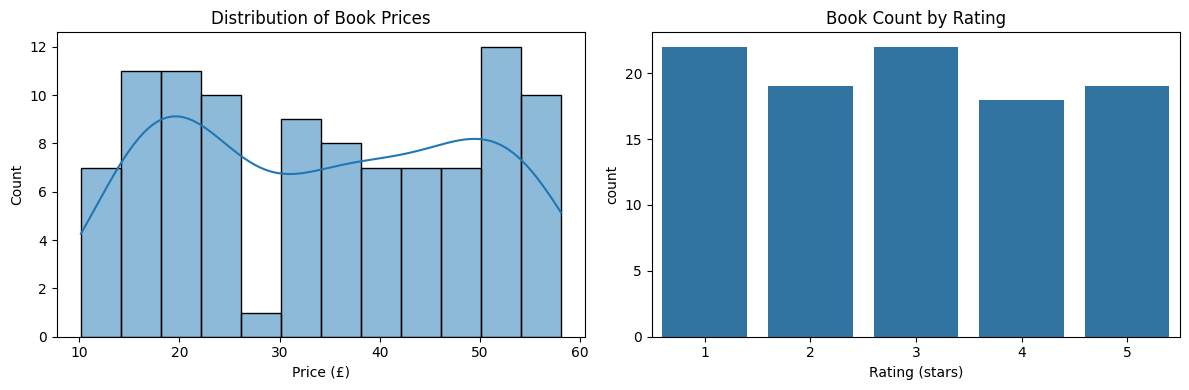

Saved dataset to: /content/books_scraped.csv


In [4]:
# Explore the price distribution and rating counts.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(books_df["Price (£)"], bins=12, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Book Prices")
axes[0].set_xlabel("Price (£)")
sns.countplot(data=books_df, x="Rating", ax=axes[1])
axes[1].set_title("Book Count by Rating")
axes[1].set_xlabel("Rating (stars)")
plt.tight_layout()
plt.show()

csv_path = "/content/books_scraped.csv"
books_df.to_csv(csv_path, index=False)
print("Saved dataset to:", csv_path)

# Practical 2 — Central Limit Theorem

**Aim:** Draw repeated random samples from book prices, calculate their means and visualize the distribution of sample means.

Population mean: £34.56
Mean of 1000 sample means: £34.77
Sample size per draw: 10


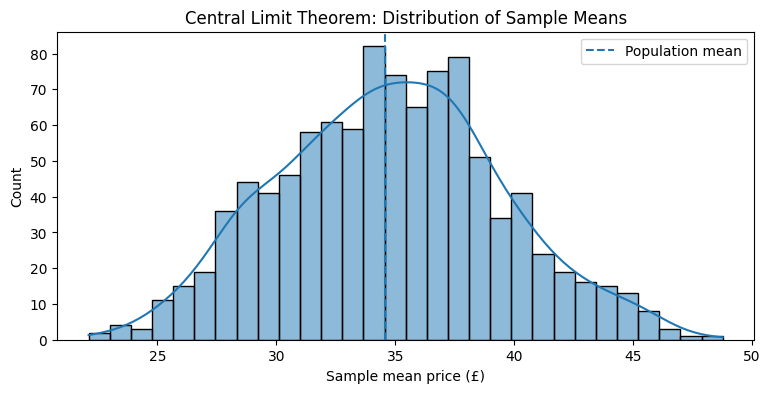

In [5]:
population = books_df["Price (£)"].dropna().to_numpy()
sample_size = min(10, len(population))
if len(population) < 2:
    raise ValueError("Need at least two prices to demonstrate CLT.")

n_samples = 1000
sample_means = [
    np.mean(np.random.choice(population, size=sample_size, replace=True))
    for _ in range(n_samples)
]
print(f"Population mean: £{np.mean(population):.2f}")
print(f"Mean of {n_samples} sample means: £{np.mean(sample_means):.2f}")
print(f"Sample size per draw: {sample_size}")

plt.figure(figsize=(9, 4))
sns.histplot(sample_means, bins=30, kde=True)
plt.axvline(np.mean(population), linestyle="--", label="Population mean")
plt.title("Central Limit Theorem: Distribution of Sample Means")
plt.xlabel("Sample mean price (£)")
plt.legend()
plt.show()

# Practical 3 — Logistic Regression Classification

**Aim:** Classify books as cheap (0) or expensive (1), using the median price as the threshold and rating as the input feature.

**Important:** This is a small teaching demonstration. A model using rating alone may perform poorly; use the actual scores printed below.

In [6]:
classification_df = books_df[["Price (£)", "Rating"]].dropna().copy()
median_price = classification_df["Price (£)"].median()
classification_df["Price_Category"] = (classification_df["Price (£)"] > median_price).astype(int)
X = classification_df[["Rating"]]
y = classification_df["Price_Category"]

if y.nunique() < 2 or y.value_counts().min() < 2:
    print("Not enough examples in each class for a stratified train/test split.")
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
    )
    logistic_model = LogisticRegression(max_iter=1000)
    logistic_model.fit(X_train, y_train)
    y_pred = logistic_model.predict(X_test)
    print(f"Median price threshold: £{median_price:.2f}")
    print("0 = cheap (price <= median); 1 = expensive (price > median)")
    print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
    print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
    print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.3f}")
    print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.3f}")
    print("\nConfusion matrix:")
    display(pd.DataFrame(confusion_matrix(y_test, y_pred), index=["Actual cheap","Actual expensive"], columns=["Predicted cheap","Predicted expensive"]))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))

Median price threshold: £34.78
0 = cheap (price <= median); 1 = expensive (price > median)
Accuracy : 0.467
Precision: 0.455
Recall   : 0.333
F1-score : 0.385

Confusion matrix:


,Predicted cheap,Predicted expensive
Actual cheap,9,6
Actual expensive,10,5



Classification report:
              precision    recall  f1-score   support

           0       0.47      0.60      0.53        15
           1       0.45      0.33      0.38        15

    accuracy                           0.47        30
   macro avg       0.46      0.47      0.46        30
weighted avg       0.46      0.47      0.46        30



# Practical 4 — Linear Regression

**Aim:** Fit a linear regression model to a small example dataset and evaluate its predictions. This practical uses a separate teaching dataset, not the scraped book prices.

Coefficient: 2.0431
Intercept: -0.3621
Mean Squared Error: 0.0384
R² score: 0.9992


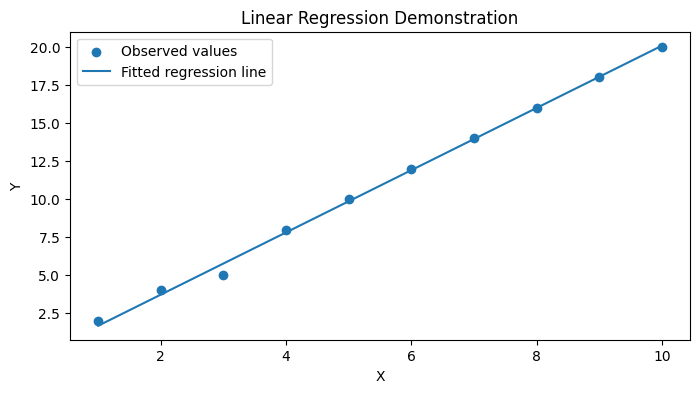

In [7]:
X_lr = np.arange(1, 11).reshape(-1, 1)
y_lr = np.array([2, 4, 5, 8, 10, 12, 14, 16, 18, 20], dtype=float)
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr, y_lr, test_size=0.20, random_state=RANDOM_STATE
)
linear_model = LinearRegression()
linear_model.fit(X_train_lr, y_train_lr)
y_pred_lr = linear_model.predict(X_test_lr)

print("Coefficient:", round(float(linear_model.coef_[0]), 4))
print("Intercept:", round(float(linear_model.intercept_), 4))
print("Mean Squared Error:", round(mean_squared_error(y_test_lr, y_pred_lr), 4))
print("R² score:", round(r2_score(y_test_lr, y_pred_lr), 4))

x_line = np.linspace(X_lr.min(), X_lr.max(), 100).reshape(-1, 1)
plt.figure(figsize=(8, 4))
plt.scatter(X_lr, y_lr, label="Observed values")
plt.plot(x_line, linear_model.predict(x_line), label="Fitted regression line")
plt.title("Linear Regression Demonstration")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

# Practical 5 — Confidence Intervals, One-Sample Z-Test and t-Test

**Aim:** Estimate the mean book price with a confidence interval and test a hypothesized mean.

The Z-test below uses the population standard deviation of the available dataset as a classroom demonstration. In real inferential work, the population standard deviation is rarely known; the one-sample t-test is often more appropriate.

In [8]:
prices = books_df["Price (£)"].dropna().to_numpy()
n = len(prices)
sample_mean = float(np.mean(prices))
sample_sd = float(np.std(prices, ddof=1))
alpha = 0.05
z_critical = stats.norm.ppf(1 - alpha/2)
t_critical = stats.t.ppf(1 - alpha/2, df=n-1)

z_ci = (sample_mean - z_critical * sample_sd/np.sqrt(n),
        sample_mean + z_critical * sample_sd/np.sqrt(n))
t_ci = (sample_mean - t_critical * sample_sd/np.sqrt(n),
        sample_mean + t_critical * sample_sd/np.sqrt(n))
print(f"Sample size: {n}")
print(f"Mean price: £{sample_mean:.2f}")
print(f"95% t confidence interval: (£{t_ci[0]:.2f}, £{t_ci[1]:.2f})")
print(f"95% z-style interval using sample SD as sigma (teaching approximation): (£{z_ci[0]:.2f}, £{z_ci[1]:.2f})")

# Demonstration hypothesis: H0 mean price = £30; H1 mean price != £30.
mu0 = 30.0
z_stat = (sample_mean - mu0) / (sample_sd / np.sqrt(n))
z_p = 2 * (1 - stats.norm.cdf(abs(z_stat)))
t_stat, t_p = stats.ttest_1samp(prices, popmean=mu0)
print(f"\nZ-style test for H0: mean = £{mu0:.2f}: z = {z_stat:.3f}, p = {z_p:.4f}")
print(f"One-sample t-test for H0: mean = £{mu0:.2f}: t = {t_stat:.3f}, p = {t_p:.4f}")
print("Decision using t-test at alpha=0.05:", "Reject H0" if t_p < alpha else "Fail to reject H0")

Sample size: 100
Mean price: £34.56
95% t confidence interval: (£31.66, £37.47)
95% z-style interval using sample SD as sigma (teaching approximation): (£31.69, £37.43)

Z-style test for H0: mean = £30.00: z = 3.116, p = 0.0018
One-sample t-test for H0: mean = £30.00: t = 3.116, p = 0.0024
Decision using t-test at alpha=0.05: Reject H0


# Practical 6 — Chi-Square Test, Covariance, Pearson and Spearman Correlation

## Part A: Chi-square test of independence
A contingency table requires categorical variables. Here, price category and rating group are derived from the scraped data.

In [9]:
chi_df = books_df[["Price (£)", "Rating"]].dropna().copy()
chi_df["Price category"] = np.where(chi_df["Price (£)"] > chi_df["Price (£)"].median(), "Expensive", "Cheap")
chi_df["Rating group"] = np.where(chi_df["Rating"] >= 4, "High rating (4–5)", "Lower rating (1–3)")
contingency = pd.crosstab(chi_df["Price category"], chi_df["Rating group"])
display(contingency)
if contingency.shape[0] >= 2 and contingency.shape[1] >= 2:
    chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)
    print(f"Chi-square statistic = {chi2:.3f}; degrees of freedom = {dof}; p-value = {chi_p:.4f}")
    print("Expected counts:")
    display(pd.DataFrame(expected, index=contingency.index, columns=contingency.columns).round(2))
    print("At alpha=0.05:", "Evidence of association (reject H0)" if chi_p < 0.05 else "Insufficient evidence of association (fail to reject H0)")
else:
    print("Chi-square test needs at least two categories in each variable.")

Rating group,High rating (4–5),Lower rating (1–3)
Price category,,
Cheap,21,29
Expensive,16,34


Chi-square statistic = 0.686; degrees of freedom = 1; p-value = 0.4074
Expected counts:


Rating group,High rating (4–5),Lower rating (1–3)
Price category,,
Cheap,18.5,31.5
Expensive,18.5,31.5


At alpha=0.05: Insufficient evidence of association (fail to reject H0)


## Part B: Covariance and correlation

Covariance matrix:


,Price (£),Rating
Price (£),214.286590,-2.536213
Rating,-2.536213,2.025354


Pearson r = -0.122, p-value = 0.2276
Spearman rho = -0.122, p-value = 0.2264
Pearson describes linear association; Spearman describes monotonic association using ranks.


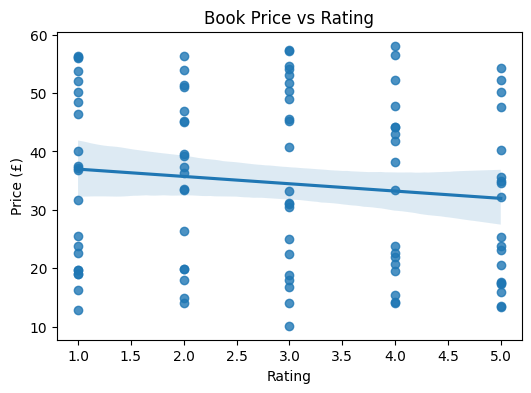

In [10]:
cor_df = books_df[["Price (£)", "Rating"]].dropna()
print("Covariance matrix:")
display(cor_df.cov())
pearson_r, pearson_p = stats.pearsonr(cor_df["Price (£)"], cor_df["Rating"])
spearman_r, spearman_p = stats.spearmanr(cor_df["Price (£)"], cor_df["Rating"])
print(f"Pearson r = {pearson_r:.3f}, p-value = {pearson_p:.4f}")
print(f"Spearman rho = {spearman_r:.3f}, p-value = {spearman_p:.4f}")
print("Pearson describes linear association; Spearman describes monotonic association using ranks.")

plt.figure(figsize=(6, 4))
sns.regplot(data=cor_df, x="Rating", y="Price (£)")
plt.title("Book Price vs Rating")
plt.show()

## Part C: Pearson/Spearman correlation hypothesis test

H₀: population correlation is zero.  
H₁: population correlation is not zero.

The p-values printed above are two-sided tests. Statistical significance does not imply causation.

In [11]:
for name, coeff, pval in [
    ("Pearson", pearson_r, pearson_p),
    ("Spearman", spearman_r, spearman_p)
]:
    decision = "Reject H0" if pval < 0.05 else "Fail to reject H0"
    print(f"{name}: coefficient={coeff:.3f}, p={pval:.4f} -> {decision} at alpha=0.05")

Pearson: coefficient=-0.122, p=0.2276 -> Fail to reject H0 at alpha=0.05
Spearman: coefficient=-0.122, p=0.2264 -> Fail to reject H0 at alpha=0.05


# Practical 7 — Two-Way ANOVA

**Aim:** Test the effects of two categorical factors and their interaction on a numeric outcome.

The live book data does not provide two naturally meaningful experimental factors. To demonstrate the method responsibly, this practical uses a clearly labelled simulated teaching dataset. Do not interpret it as a finding about the scraped books.

In [12]:
rng = np.random.default_rng(RANDOM_STATE)
n_per_cell = 12
rows = []
for genre in ["Fiction", "Non-fiction"]:
    for rating_group in ["Lower", "Higher"]:
        base = 28 + (8 if genre == "Non-fiction" else 0) + (5 if rating_group == "Higher" else 0)
        for value in base + rng.normal(0, 5, n_per_cell):
            rows.append({"Genre": genre, "RatingGroup": rating_group, "ExamplePrice": value})
anova_df = pd.DataFrame(rows)
print("SIMULATED teaching data for ANOVA:")
display(anova_df.head())

anova_model = ols("ExamplePrice ~ C(Genre) * C(RatingGroup)", data=anova_df).fit()
anova_table = sm.stats.anova_lm(anova_model, typ=2)
display(anova_table)
print("Interpretation: inspect each factor's p-value and the interaction p-value. At alpha=0.05, p < 0.05 indicates evidence of an effect, subject to ANOVA assumptions.")

SIMULATED teaching data for ANOVA:


,Genre,RatingGroup,ExamplePrice
0,Fiction,Lower,29.523585
1,Fiction,Lower,22.800079
2,Fiction,Lower,31.752256
3,Fiction,Lower,32.702824
4,Fiction,Lower,18.244824


,sum_sq,df,F,PR(>F)
C(Genre),968.713401,1.0,61.809138,6.374426e-10
C(RatingGroup),325.028222,1.0,20.738553,4.141121e-05
C(Genre):C(RatingGroup),12.506088,1.0,0.797956,3.765652e-01
Residual,689.596900,44.0,NaN,NaN


Interpretation: inspect each factor's p-value and the interaction p-value. At alpha=0.05, p < 0.05 indicates evidence of an effect, subject to ANOVA assumptions.


# Practical 8 — Streamlit Book Price Analyzer Dashboard

This final practical launches a **Streamlit** dashboard. The UI performs descriptive analysis on the book dataset; the Logistic Regression and Linear Regression models were demonstrated in Practicals 3 and 4. The UI does not claim to train or deploy those models.

Run the next cell to create the Streamlit app, then run the launch cell. In Google Colab, run the launch cell and open the preview link it prints. Run Practical 1 first.


In [13]:
%%writefile /content/streamlit_app.py
import os
import pandas as pd
import streamlit as st
import plotly.express as px

st.set_page_config(page_title="Book Price Analyzer", page_icon="📚", layout="wide")
st.title("📚 Book Price Analyzer")
st.caption("Book Price, Rating & Review Analysis")
st.markdown("Explore book prices, ratings, filter the catalogue, and download results.")

DATA_PATH = "/content/books_scraped.csv"
if not os.path.exists(DATA_PATH):
    st.error("Dataset not found. Run the notebook cells through Practical 1 first so books_scraped.csv is created.")
    st.stop()

df = pd.read_csv(DATA_PATH)
required = ["Title", "Price (£)", "Rating", "Availability", "Product URL"]
for col in required:
    if col not in df.columns:
        st.error(f"Required column missing: {col}")
        st.stop()
df["Price (£)"] = pd.to_numeric(df["Price (£)"], errors="coerce")
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df = df.dropna(subset=["Title", "Price (£)", "Rating"])
if df.empty:
    st.warning("The dataset contains no usable book records.")
    st.stop()

min_data = float(df["Price (£)"].min())
max_data = float(df["Price (£)"].max())
with st.sidebar:
    st.header("🔎 Filters")
    title_search = st.text_input("Book title contains", placeholder="e.g. love, history, travel")
    if min_data == max_data:
        price_range = (min_data, max_data)
        st.caption(f"All books have the same price: £{min_data:.2f}")
    else:
        price_range = st.slider("Price range (£)", min_value=min_data, max_value=max_data,
                                value=(min_data, max_data), step=0.5)
    min_rating = st.selectbox("Minimum rating", [0, 1, 2, 3, 4, 5], format_func=lambda x: "Any rating" if x == 0 else f"{x} star{'s' if x != 1 else ''} and above")
    chart_type = st.selectbox("Chart type", ["Price distribution", "Average price by rating", "Price vs rating"])
    sort_by = st.selectbox("Sort catalogue", ["Price: low to high", "Price: high to low", "Rating: high to low", "Title: A to Z"])
    max_results = st.slider("Rows to show", min_value=5, max_value=100, value=25, step=5)

filtered = df.copy()
if title_search.strip():
    filtered = filtered[filtered["Title"].str.contains(title_search.strip(), case=False, na=False, regex=False)]
filtered = filtered[filtered["Price (£)"].between(price_range[0], price_range[1])]
if min_rating > 0:
    filtered = filtered[filtered["Rating"] >= min_rating]

sort_options = {
    "Price: low to high": ("Price (£)", True),
    "Price: high to low": ("Price (£)", False),
    "Rating: high to low": ("Rating", False),
    "Title: A to Z": ("Title", True),
}
col, ascending = sort_options[sort_by]
filtered = filtered.sort_values(col, ascending=ascending)

if filtered.empty:
    st.warning("No books match these filters. Try clearing the title search or widening the price range.")
else:
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Matching books", f"{len(filtered):,}")
    c2.metric("Average price", f"£{filtered['Price (£)'].mean():.2f}")
    c3.metric("Lowest price", f"£{filtered['Price (£)'].min():.2f}")
    c4.metric("Average rating", f"{filtered['Rating'].mean():.2f} / 5")

    st.subheader("📊 Book analysis")
    if chart_type == "Price distribution":
        fig = px.histogram(filtered, x="Price (£)", nbins=12, title="Book Price Distribution", template="plotly_white")
    elif chart_type == "Average price by rating":
        grouped = filtered.groupby("Rating", as_index=False)["Price (£)"].mean()
        fig = px.bar(grouped, x="Rating", y="Price (£)", title="Average Price by Rating", template="plotly_white")
    else:
        fig = px.scatter(filtered, x="Rating", y="Price (£)", hover_name="Title", title="Price vs Rating", template="plotly_white")
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("📚 Book catalogue")
    st.dataframe(filtered.head(max_results), use_container_width=True, hide_index=True)
    st.download_button("⬇️ Download filtered CSV", data=filtered.to_csv(index=False).encode("utf-8"),
                       file_name="book_price_analysis_filtered.csv", mime="text/csv")

with st.expander("About this dashboard"):
    st.write("The dashboard filters and summarizes the dataset created in Practical 1. It is a descriptive analytics interface and does not train a machine-learning model.")


Writing /content/streamlit_app.py


In [14]:
# Launch Streamlit inside Google Colab and print a working preview link.
# Run Practical 1 first so /content/books_scraped.csv exists.

import subprocess
import time
import os
import sys
from pathlib import Path

app_path = Path("/content/streamlit_app.py")
data_path = Path("/content/books_scraped.csv")

if not app_path.exists():
    raise FileNotFoundError("App file is missing. Run the previous cell that writes streamlit_app.py first.")
if not data_path.exists():
    raise FileNotFoundError("Dataset is missing. Run Practical 1 first to create /content/books_scraped.csv.")

# Stop only processes listening on the dashboard port, if lsof is available.
try:
    old_pids = subprocess.run(
        ["bash", "-lc", "fuser -k 8501/tcp"],
        capture_output=True, text=True, timeout=5
    )
except Exception:
    pass

log_path = "/content/streamlit.log"
log_file = open(log_path, "w")
streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run", str(app_path),
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--browser.gatherUsageStats=false",
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
)

# Wait until Streamlit answers locally or report the log.
import requests
ready = False
for _ in range(20):
    if streamlit_process.poll() is not None:
        break
    try:
        response = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=2)
        if response.ok:
            ready = True
            break
    except Exception:
        pass
    time.sleep(1)

if not ready:
    print("Streamlit did not become ready. Last log lines:")
    try:
        print("\\n".join(Path(log_path).read_text(errors="ignore").splitlines()[-35:]))
    except Exception as error:
        print(error)
else:
    try:
        from google.colab.output import eval_js
        preview_url = eval_js("google.colab.kernel.proxyPort(8501)")
        print("✅ Streamlit dashboard is running. Open this link:")
        print(preview_url)
    except Exception as error:
        print("Streamlit is running on port 8501, but the Colab preview link could not be generated.")
        print("Try rerunning this launch cell. Details:", error)
        print("Log file:", log_path)


✅ Streamlit dashboard is running. Open this link:
https://8501-m-s-usc1c3-140zuol9b3kuh-c.us-central1.prod.r.colab.dev
